## Semantic Segmentation with U-Net

## Project Overview

This project implements a semantic segmentation system using the U-Net architecture, developed with TensorFlow/Keras. The model uses an encoder-decoder architecture with skip connections and is trained on the CARLA dataset to perform pixel-level classification, assigning each pixel in an input image to one of 23 semantic classes.

## Architecture and Methodology

<b>1) U-Net Architecture:</b> Implements an encoder-decoder network for semantic segmentation.

<b>2) Encoder:</b> Extracts spatial features from input images through successive convolutional and pooling layers.

<b>3) Decoder:</b> Reconstructs spatial resolution to generate pixel-level class predictions.

<b>4) Skip Connections:</b> Transfers feature information from the encoder to the corresponding decoder layers to preserve spatial details.

<b>5) Model Training:</b> Trains the network on the CARLA dataset to classify every image pixel into one of 23 classes.

## Key Feature

The system performs pixel-level semantic segmentation, enabling the identification and classification of different objects and scene elements within an image.

In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras import layers

In [10]:
img_h, img_w = 96, 128
n_classes = 23
n_filters = 32
batch_size = 32
epochs = 20

In [11]:
image_dir = "data/CameraRGB"
mask_dir = "data/CameraSeg"
files = sorted(os.listdir(image_dir))
def load_pair(image_path, mask_path):
    img = tf.image.decode_png(tf.io.read_file(image_path), channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, (img_h, img_w), method='nearest')
    mask = tf.image.decode_png(tf.io.read_file(mask_path), channels=3)
    mask = tf.reduce_max(mask, axis=-1, keepdims=True)
    mask = tf.image.resize(mask, (img_h, img_w), method='nearest')
    return img, mask

train_dataset = (tf.data.Dataset
                .from_tensor_slices(([os.path.join(image_dir, f) for f in files],
                                    [os.path.join(mask_dir, f) for f in files]))
                .map(load_pair)
                .cache()
                .shuffle(500)
                .batch(batch_size))

In [12]:
def conv_block(x, filters, dropout=0.0, pool=True):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    skip = x
    if pool:
        x = layers.MaxPooling2D(2)(x)
    return x, skip
    
def up_block(x, skip, filters):
    x = layers.Conv2DTranspose(filters, 3, strides=2, padding='same')(x)
    x = layers.concatenate([x, skip], axis=3)
    for _ in range(2):
        x = layers.Conv2D(filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(x)
    return x
    
def build_unet(input_size=(img_h, img_w, 3), filters=n_filters, classes=n_classes):
    inputs = layers.Input(input_size)
    # Encoder (contracting path)
    x, s1 = conv_block(inputs, filters)
    x, s2 = conv_block(x, filters * 2)
    x, s3 = conv_block(x, filters * 4)
    x, s4 = conv_block(x, filters * 8, dropout=0.3)
    x, _ = conv_block(x, filters * 16, dropout=0.3, pool=False) # bottleneck
    # Decoder (expanding path)
    x = up_block(x, s4, filters * 8)
    x = up_block(x, s3, filters * 4)
    x = up_block(x, s2, filters * 2)
    x = up_block(x, s1, filters)
    x = layers.Conv2D(filters, 3, activation="relu", padding="same",
    kernel_initializer="he_normal")(x)
    outputs = layers.Conv2D(classes, 1, padding="same")(x) # raw scores (logits)
    return tf.keras.Model(inputs, outputs)
unet = build_unet()

In [13]:
unet.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 96, 128, 3)        │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_20 (Conv2D)            │ (None, 96, 128, 32)       │             896 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_21 (Conv2D)            │ (None, 96, 128, 32)       │           9,248 │ conv2d_20[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_4               │ (None, 48, 64, 32)        │               0 │ conv2d_21[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_22 (Conv2D)            │ (None, 48, 64, 64)        │          18,496 │ max_pooling2d_4[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_23 (Conv2D)            │ (None, 48, 64, 64)        │          36,928 │ conv2d_22[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_5               │ (None, 24, 32, 64)        │               0 │ conv2d_23[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_24 (Conv2D)            │ (None, 24, 32, 128)       │          73,856 │ max_pooling2d_5[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_25 (Conv2D)            │ (None, 24, 32, 128)       │         147,584 │ conv2d_24[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_6               │ (None, 12, 16, 128)       │               0 │ conv2d_25[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_26 (Conv2D)            │ (None, 12, 16, 256)       │         295,168 │ max_pooling2d_6[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_27 (Conv2D)            │ (None, 12, 16, 256)       │         590,080 │ conv2d_26[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_2 (Dropout)           │ (None, 12, 16, 256)       │               0 │ conv2d_27[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_7               │ (None, 6, 8, 256)         │               0 │ dropout_2[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_28 (Conv2D)            │ (None, 6, 8, 512)         │       1,180,160 │ max_pooling2d_7[0][0]      │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 8,640,471 (32.96 MB)

 Trainable params: 8,640,471 (32.96 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
unet.compile(optimizer="adam",loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),metrics=["accuracy"])
history = unet.fit(train_dataset, epochs=epochs)
unet.save("unet_segmentation.keras")

Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 232s 6s/step - accuracy: 0.3920 - loss: 1.9826
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 192s 6s/step - accuracy: 0.6202 - loss: 1.2165
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 198s 6s/step - accuracy: 0.7744 - loss: 0.7496
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 201s 6s/step - accuracy: 0.8462 - loss: 0.5100
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 208s 7s/step - accuracy: 0.8713 - loss: 0.4257
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 193s 6s/step - accuracy: 0.8870 - loss: 0.3734
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 192s 6s/step - accuracy: 0.9034 - loss: 0.3199
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 186s 6s/step - accuracy: 0.9127 - loss: 0.2849
Epoch 9/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 185s 6s/step - accuracy: 0.9186 - loss: 0.2629
Epoch 10/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 185s 6s/step - accuracy: 0.9263 - loss: 0.2334
Epoch 11/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 185s 6s/step - accuracy: 0.9323 - loss: 0.2120
Epoch 12/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 185s 6s/step - accuracy:

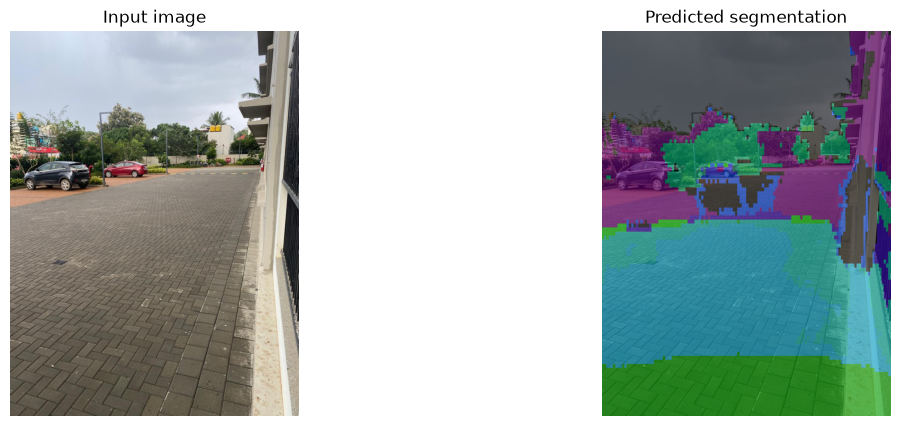

In [19]:
def segment(image_path, model):
    """Returns the original image and its predicted class mask (same height and width)."""
    img = Image.open(image_path).convert("RGB")
    x = np.array(img.resize((img_w, img_h)), dtype=np.float32) / 255.0
    scores = model.predict(x[np.newaxis], verbose=0)[0] # (96, 128, 23)
    mask = np.argmax(scores, axis=-1).astype(np.uint8) # (96, 128)
    mask = Image.fromarray(mask).resize(img.size, Image.NEAREST)
    return img, np.array(mask)
model = tf.keras.models.load_model("unet_segmentation.keras")
img, mask = segment("test_3.jpeg", model)
fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(1, 2, 1); ax.imshow(img); ax.set_title("Input image"); ax.axis("off")
ax = fig.add_subplot(1, 2, 2); ax.imshow(img)
ax.imshow(mask, cmap="nipy_spectral", alpha=0.6, vmin=0, vmax=n_classes - 1)
ax.set_title("Predicted segmentation"); ax.axis("off")
plt.show()